# Replay one experimental game

This notebook replays one Choi 2020 game and shows:

- the replay setup in separate stages
- the actions printed per step
- the directed ownership graph after each recorded state
- multiple replay metrics plotted from a list of observers


## Imports


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import scienceplots

project_root = Path.cwd()
if not (project_root / "network_creation").exists():
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

from network_creation.data.choi_2020 import (build_replay_simulator,
                                             list_choi_2020_configs,
                                             load_choi_2020_normalized_data,
                                             run_choi_2020_replay_batch)
from network_creation.observers import (
    ActionCountObserver,
    ActionPrintObserver,
    DensityObserver,
    DistanceObserver,
    GlobalClosenessCentralityObserver,
    IndegreeObserver,
    StateHistoryObserver,
    HubPersistenceObserver,
    CentralPointOfDominanceObserver
)
from network_creation.plotting.episode_series import \
    plot_episode_series_observer
from network_creation.plotting.ownership_history import \
    build_circle_layout, plot_ownership_history


In [2]:
plt.style.use(style="science")

In [3]:
fixed_layout = build_circle_layout(n_nodes=6)


## Replay data


In [4]:
data_root = project_root / "data/choi_2020/raw"
available_configs = list_choi_2020_configs(data_root)
available_configs[:5]

(Choi2020ReplayConfig(group_size=10, session_id=1, group_id=1, round_id=2, source_path=PosixPath('/home/hdahmou/Network_creation/data/choi_2020/raw/Linking_10_1/data.csv')),
 Choi2020ReplayConfig(group_size=10, session_id=1, group_id=1, round_id=3, source_path=PosixPath('/home/hdahmou/Network_creation/data/choi_2020/raw/Linking_10_1/data.csv')),
 Choi2020ReplayConfig(group_size=10, session_id=1, group_id=1, round_id=4, source_path=PosixPath('/home/hdahmou/Network_creation/data/choi_2020/raw/Linking_10_1/data.csv')),
 Choi2020ReplayConfig(group_size=10, session_id=1, group_id=1, round_id=5, source_path=PosixPath('/home/hdahmou/Network_creation/data/choi_2020/raw/Linking_10_1/data.csv')),
 Choi2020ReplayConfig(group_size=10, session_id=1, group_id=1, round_id=6, source_path=PosixPath('/home/hdahmou/Network_creation/data/choi_2020/raw/Linking_10_1/data.csv')))

## Observer settings


In [5]:
action_printer = ActionPrintObserver(observation_frequency=1, print_empty_steps=False)
metric_observers = [
    DensityObserver(observation_frequency=1, aggregations=()),
    IndegreeObserver(observation_frequency=1, aggregations=()),
    GlobalClosenessCentralityObserver(observation_frequency=1, aggregations=()),
    DistanceObserver(observation_frequency=1, aggregations=()),
    ActionCountObserver(observation_frequency=1, aggregations=()),
    HubPersistenceObserver(observation_frequency=1, window_size=10, aggregations=()),
    CentralPointOfDominanceObserver(observation_frequency=1, aggregations=()),
]
state_history_observer = StateHistoryObserver(observation_frequency=1, keep_runs=False)

(
    action_printer.__class__.__name__,
    [observer.__class__.__name__ for observer in metric_observers],
    state_history_observer.__class__.__name__,
)


('ActionPrintObserver',
 ['DensityObserver',
  'IndegreeObserver',
  'GlobalClosenessCentralityObserver',
  'DistanceObserver',
  'ActionCountObserver',
  'HubPersistenceObserver',
  'CentralPointOfDominanceObserver'],
 'StateHistoryObserver')

## Build the replay simulator


In [6]:
config = available_configs[0]
config

Choi2020ReplayConfig(group_size=10, session_id=1, group_id=1, round_id=2, source_path=PosixPath('/home/hdahmou/Network_creation/data/choi_2020/raw/Linking_10_1/data.csv'))

In [7]:
max_steps = load_choi_2020_normalized_data(config).max_step
max_steps

359

In [8]:
simulator = build_replay_simulator(
    config=config,
    observers=(action_printer, *metric_observers, state_history_observer),
    max_steps=max_steps,
)

fixed_layout = build_circle_layout(simulator.n_agents)
(simulator.mode, simulator.max_steps, simulator.n_agents)


(<SchedulingMode.SIMULTANEOUS: 'SIMULTANEOUS'>, 359, 10)

## Run the replay


In [9]:
simulator.run(n_episodes=1)

(
    simulator.n_completed_episodes,
    state_history_observer.steps[-1],
    {observer.__class__.__name__: observer.steps[-1] for observer in metric_observers},
)



step 6
  8: ADD->2

step 7
  2: ADD->4
  3: ADD->5
  6: ADD->4
  8: ADD->3, ADD->4

step 8
  1: ADD->5
  2: ADD->7

step 9
  5: ADD->7
  7: ADD->0
  8: ADD->6
  9: ADD->8

step 10
  8: ADD->0

step 11
  4: ADD->8
  6: DELETE->4

step 12
  1: ADD->4

step 13
  1: DELETE->5
  7: DELETE->0

step 14
  2: DELETE->7, ADD->8

step 15
  2: DELETE->8
  5: ADD->8

step 16
  2: ADD->9

step 17
  5: DELETE->7

step 18
  2: DELETE->9
  3: DELETE->5
  8: ADD->7

step 19
  1: ADD->8
  2: DELETE->4

step 20
  1: DELETE->4
  2: ADD->7

step 22
  2: DELETE->7

step 23
  2: ADD->6

step 24
  9: ADD->4, DELETE->8

step 26
  2: DELETE->6

step 28
  8: ADD->9

step 31
  3: ADD->7
  5: ADD->9

step 32
  3: DELETE->7
  5: DELETE->8

step 34
  5: ADD->8

step 35
  3: ADD->8
  5: DELETE->9

step 36
  2: ADD->5

step 37
  2: DELETE->5

step 39
  2: ADD->1
  3: DELETE->8

step 40
  2: DELETE->1

step 41
  2: ADD->0
  8: DELETE->4

step 42
  2: DELETE->0

step 43
  2: ADD->7
  5: ADD->2

step 44
  2: DELETE->7
  

(1,
 np.int64(359),
 {'DensityObserver': np.int64(359),
  'IndegreeObserver': np.int64(359),
  'GlobalClosenessCentralityObserver': np.int64(359),
  'DistanceObserver': np.int64(359),
  'ActionCountObserver': np.int64(359),
  'HubPersistenceObserver': np.int64(359),
  'CentralPointOfDominanceObserver': np.int64(359)})

## Directed ownership graph after each recorded state


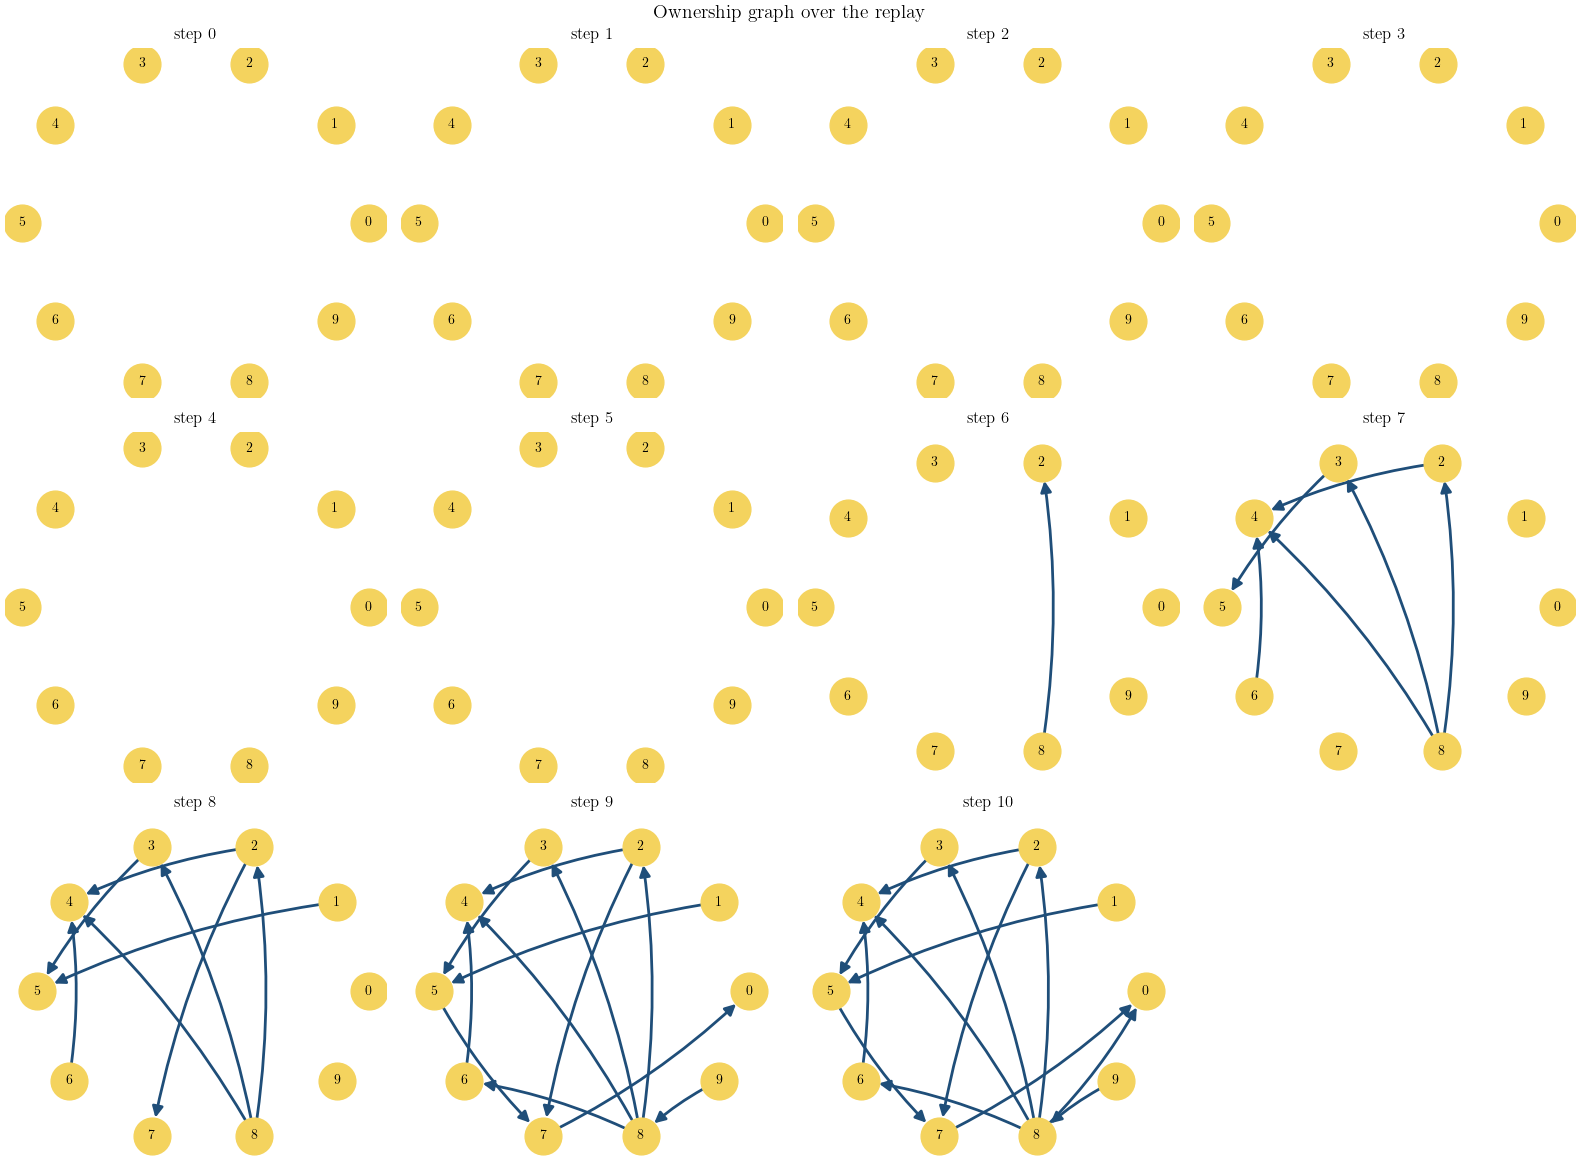

In [10]:
plot_mask = state_history_observer.steps <= 10
plot_ownership_history(
    steps=state_history_observer.steps[plot_mask],
    ownership_matrices=state_history_observer.ownership_matrices[plot_mask],
    layout=fixed_layout,
    figure_title="Ownership graph over the replay",
    max_cols=4,
)
plt.show()


## Metrics across the replay


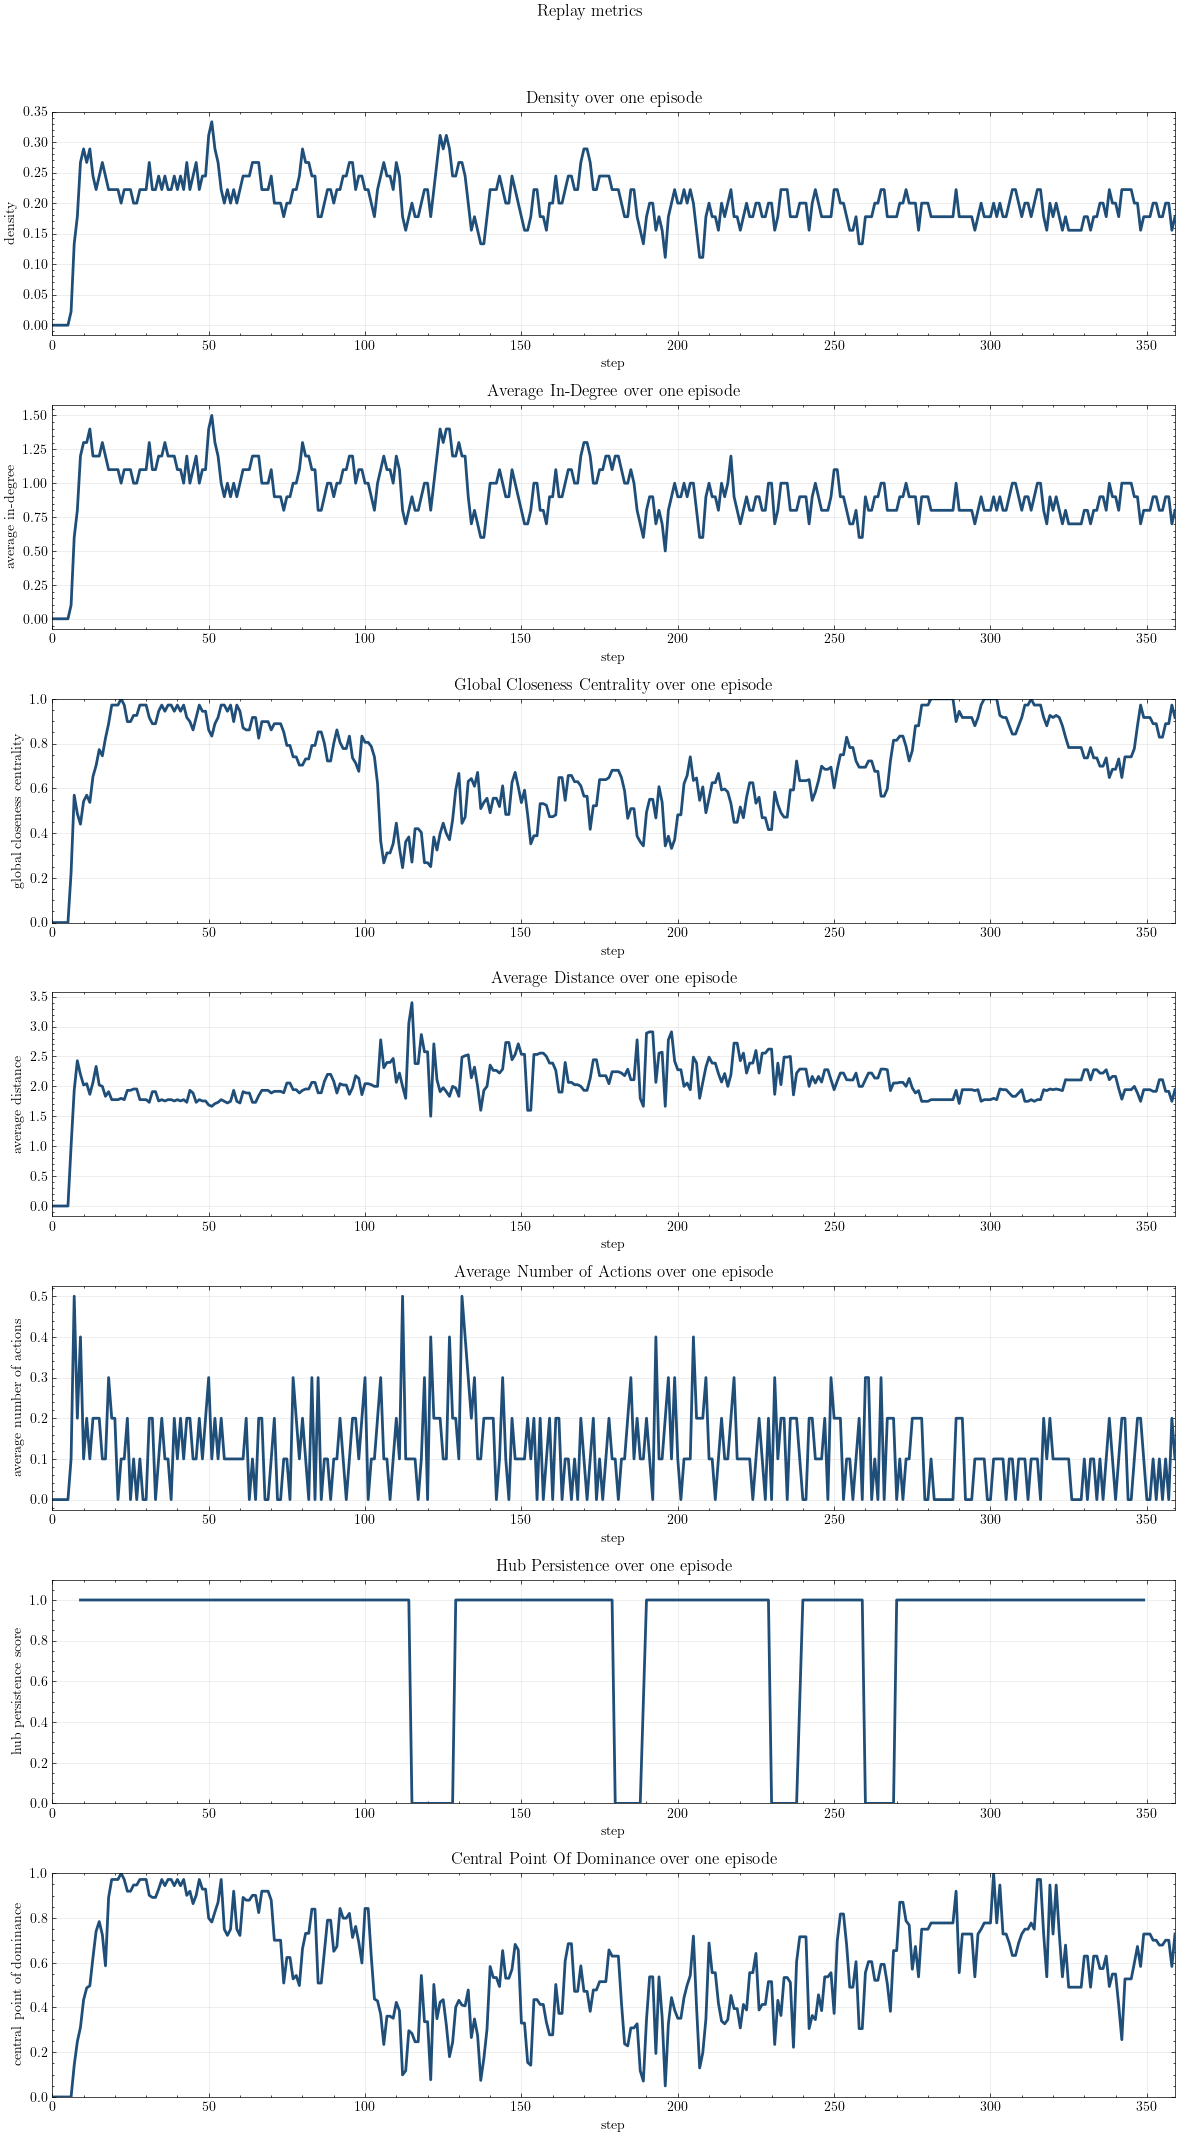

In [11]:
figure, axes = plt.subplots(
    len(metric_observers),
    1,
    figsize=(12, 3 * len(metric_observers)),
    squeeze=False,
)
for observer, axis in zip(metric_observers, axes.ravel()):
    plot_episode_series_observer(observer=observer, ax=axis)
figure.suptitle("Replay metrics", y=1.02)
figure.tight_layout()
plt.show()


## Aggregate metrics across group sizes


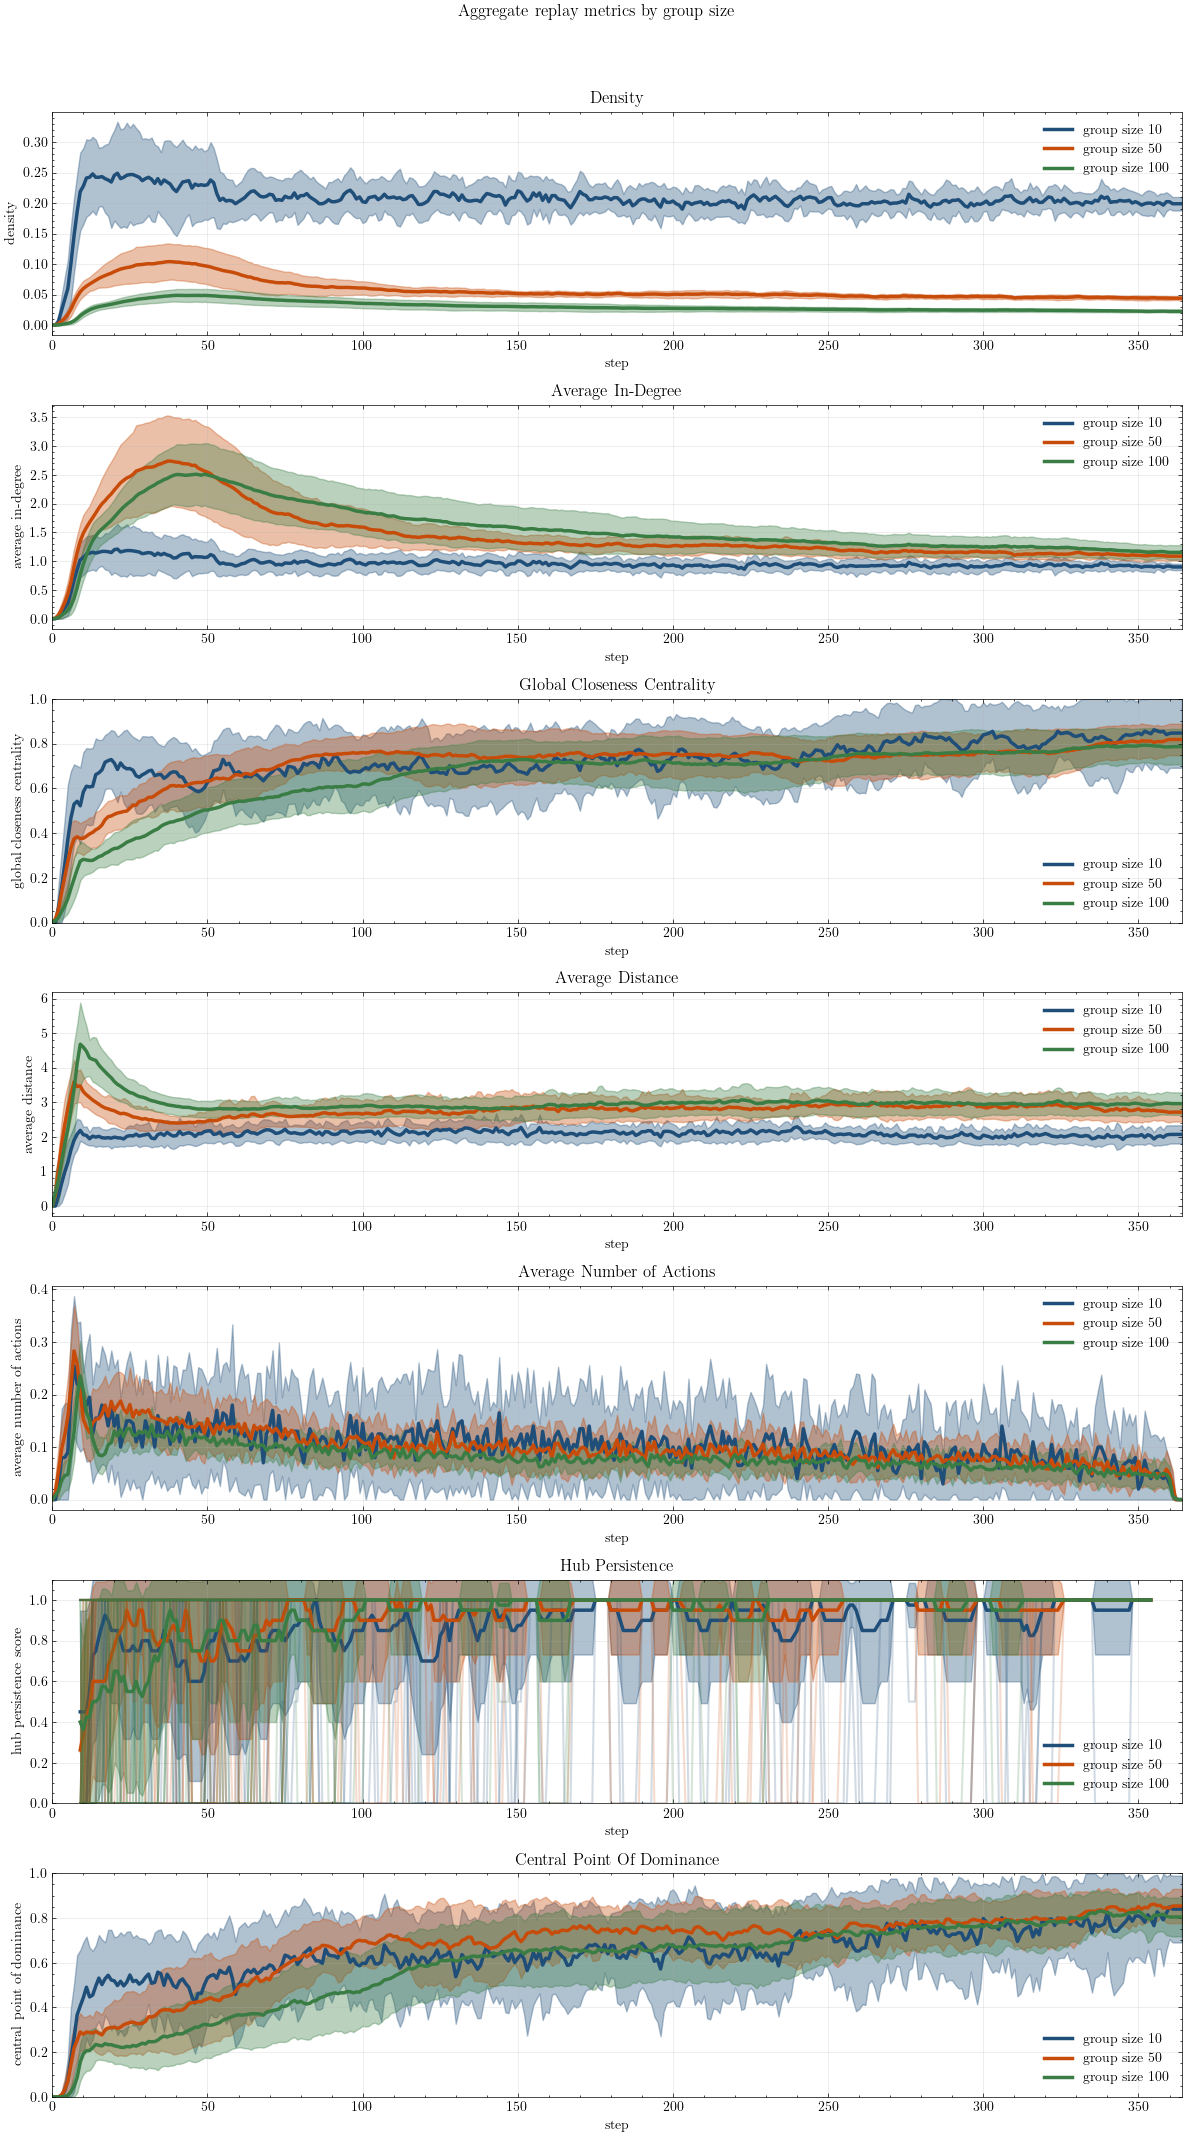

In [12]:
group_sizes = [10, 50, 100]
group_colors = ["#1f4e79", "#c84c09", "#3a7d44"]
metric_observer_builders = [
    lambda: DensityObserver(observation_frequency=1, aggregations=("mean", "std")),
    lambda: IndegreeObserver(observation_frequency=1, aggregations=("mean", "std")),
    lambda: GlobalClosenessCentralityObserver(observation_frequency=1, aggregations=("mean", "std")),
    lambda: DistanceObserver(observation_frequency=1, aggregations=("mean", "std")),
    lambda: ActionCountObserver(observation_frequency=1, aggregations=("mean", "std")),
    lambda: HubPersistenceObserver(observation_frequency=1, window_size=10, aggregations=("mean", "std", "runs")),
    lambda: CentralPointOfDominanceObserver(observation_frequency=1, aggregations=("mean", "std")),
]
max_steps = 364
aggregate_metrics_by_group_size = {}
for group_size in group_sizes:
    group_configs = tuple(
        replay_config
        for replay_config in available_configs
        if replay_config.group_size == group_size
    )
    aggregate_metric_observers = [builder() for builder in metric_observer_builders]
    run_choi_2020_replay_batch(
        configs=group_configs,
        observers=tuple(aggregate_metric_observers),
        max_steps=max_steps,
    )
    aggregate_metrics_by_group_size[group_size] = aggregate_metric_observers

figure, axes = plt.subplots(
    len(metric_observer_builders),
    1,
    figsize=(12, 3 * len(metric_observer_builders)),
    squeeze=False,
)
for metric_idx, axis in enumerate(axes.ravel()):
    reference_observer = aggregate_metrics_by_group_size[group_sizes[0]][metric_idx]
    for group_size, color in zip(group_sizes, group_colors):
        observer = aggregate_metrics_by_group_size[group_size][metric_idx]
        plot_episode_series_observer(
            observer=observer,
            ax=axis,
            color=color,
            band_color=color,
            label=f"group size {group_size}",
            set_title=False,
            show_runs=True
        )
    axis.set_title(reference_observer.label)

figure.suptitle("Aggregate replay metrics by group size", y=1.02)
figure.tight_layout()
plt.show()
